# Seleksi Fitur dengan Information Gain

Dataset: `Dataset_Latihan_Preprocessing.csv`
Target: `churn_3bln` (1 = churn, 0 = tidak churn)

Notebook ini memakai Information Gain (IG) untuk memilih fitur yang berguna untuk memprediksi churn.

Konsep singkatnya:
- **Entropi $H(S)$**: ukuran seberapa campur kelas pada target. Nilainya 0 kalau semua data satu kelas, dan 1 kalau kelasnya 50:50.
- **Entropi bersyarat $H(S \mid A)$**: entropi yang tersisa setelah data dikelompokkan berdasarkan fitur $A$.
- **Information Gain**: $IG(S,A) = H(S) - H(S \mid A)$. Makin besar IG, makin berguna fiturnya.

Langkah-langkah:
1. Load data
2. Cek data
3. Hitung entropi target
4. Buat fungsi IG
5. Contoh hitung IG manual
6. Hitung IG semua fitur
7. Visualisasi
8. Pilih fitur dan simpan dataset
9. Kesimpulan

### 1. Load Library dan Dataset

In [1]:
import pandas as pd
import numpy as np
import math
from collections import Counter
import matplotlib.pyplot as plt

# Membaca dataset
df = pd.read_csv('Dataset_Latihan_Preprocessing.csv')
print(f"Dataset berhasil dimuat dengan {df.shape[0]} baris dan {df.shape[1]} kolom.")
df.head()

Dataset berhasil dimuat dengan 1000 baris dan 22 kolom.


,id_pelanggan,usia_tahun,kota,kanal_akuisisi,tingkat_member,metode_pembayaran,langganan_newsletter,lama_member_bulan,jumlah_transaksi_6bln,rata_nilai_transaksi_rp,...,jumlah_keluhan_6bln,skor_kepuasan,persen_diskon_rata,jumlah_kunjungan_30hari,pengeluaran_bulanan_rp,kode_acak,warna_favorit,negara,kolom_hampir_kosong,churn_3bln
0,PLG0001,34.0,Jakarta,Iklan,Silver,Transfer Bank,Ya,33.0,7.0,280000.0,...,0.0,8.6,29.1,5.0,3380000.0,4262,Biru,Indonesia,NaN,0
1,PLG0002,43.0,Yogyakarta,Marketplace,Gold,E-Wallet,Tidak,15.0,11.0,226000.0,...,NaN,7.6,20.5,14.0,3260000.0,8377,Kuning,Indonesia,NaN,0
2,PLG0003,27.0,Jakarta,Iklan,Bronze,Kartu Kredit,Ya,13.0,9.0,431000.0,...,0.0,10.0,2.1,11.0,5070000.0,7000,Kuning,Indonesia,A,0
3,PLG0004,57.0,Jakarta,Referral,Platinum,COD,Ya,6.0,11.0,324000.0,...,0.0,NaN,29.8,NaN,2740000.0,7210,Kuning,Indonesia,NaN,0
4,PLG0005,27.0,Surabaya,Organik,Silver,Transfer Bank,Tidak,28.0,6.0,NaN,...,0.0,NaN,13.9,5.0,2150000.0,3037,Hijau,Indonesia,NaN,0


**Penjelasan:**

Dataset punya 1000 baris dan 22 kolom (21 fitur + 1 target). Dari 5 baris pertama sudah terlihat ada nilai kosong (`NaN`), misalnya di `rata_nilai_transaksi_rp` dan `skor_kepuasan`. Ada juga kolom yang sepertinya tidak berhubungan dengan churn, seperti `kode_acak`, `warna_favorit`, dan `negara`.

### 2. Cek Data

Cek tipe data, jumlah nilai unik, dan jumlah nilai kosong di tiap kolom. Ini perlu karena cara menghitung IG untuk fitur numerik dan kategorikal berbeda.

In [2]:
profil = pd.DataFrame({
    'Tipe Data'     : df.dtypes.astype(str),
    'Nilai Unik'    : df.nunique(),
    'Jumlah Kosong' : df.isnull().sum(),
    '% Kosong'      : (df.isnull().mean() * 100).round(1),
})
profil

,Tipe Data,Nilai Unik,Jumlah Kosong,% Kosong
id_pelanggan,str,1000,0,0.0
usia_tahun,float64,58,48,4.8
kota,str,5,38,3.8
kanal_akuisisi,str,4,41,4.1
tingkat_member,str,4,44,4.4
metode_pembayaran,str,4,29,2.9
langganan_newsletter,str,2,21,2.1
lama_member_bulan,float64,60,42,4.2
jumlah_transaksi_6bln,float64,22,36,3.6
rata_nilai_transaksi_rp,float64,456,74,7.4


**Penjelasan:**

- `id_pelanggan` punya 1000 nilai unik, artinya setiap baris ID-nya berbeda. Kolom ini tidak dipakai sebagai fitur.
- `kolom_hampir_kosong` kosong 90,3%.
- `negara` hanya punya 1 nilai, jadi tidak mungkin bisa membedakan churn dan tidak churn.
- Kolom lain kosongnya sekitar 2-12%. Kalau pakai `dropna`, banyak data yang hilang, jadi nilai kosong ditangani di dalam fungsi IG.
- Kolom angka dengan banyak nilai unik dianggap numerik kontinu. Kolom teks atau angka dengan sedikit nilai unik (misalnya `jumlah_keluhan_6bln` yang isinya 0-4) dianggap kategorikal.

### 3. Entropi Target

Rumus entropi:

$$H(S) = - \sum_{i=1}^{k} P(y_i) \log_2 P(y_i)$$

$P(y_i)$ adalah proporsi kelas ke-$i$. Untuk 2 kelas, nilainya antara 0 sampai 1.

Sebagai gambaran, berikut contoh entropi untuk 100 data dengan komposisi kelas yang berbeda:

In [3]:
def hitung_entropi(labels):
    # Menghitung Shannon Entropy (dalam satuan bit) dari sekumpulan label
    n = len(labels)
    if n == 0:
        return 0.0
    ent = 0.0
    for jumlah in Counter(labels).values():
        p = jumlah / n                 # proporsi kelas
        ent -= p * math.log2(p)        # -p * log2(p)
    return ent

# Contoh: 100 pelanggan dengan komposisi churn yang berbeda-beda
contoh = []
for n_churn in [0, 10, 24, 50]:
    label = [1] * n_churn + [0] * (100 - n_churn)
    contoh.append({'Komposisi (Setia : Churn)': f'{100 - n_churn} : {n_churn}',
                   'Entropi (bit)': round(hitung_entropi(label), 4)})
pd.DataFrame(contoh)

,Komposisi (Setia : Churn),Entropi (bit)
0,100 : 0,0.000
1,90 : 10,0.469
2,76 : 24,0.795
3,50 : 50,1.000


**Penjelasan:**

Kalau semua data satu kelas (100:0), entropinya 0. Makin seimbang kelasnya, makin tinggi entropinya, sampai 1 untuk 50:50. Komposisi 76:24 mirip dengan dataset ini, entropinya sekitar 0,79.

Fitur yang bagus adalah fitur yang bisa membagi data menjadi kelompok-kelompok dengan entropi rendah.

Sekarang hitung entropi untuk `churn_3bln`:

In [4]:
target = df['churn_3bln']
total_samples = len(target)

print("Distribusi Target churn_3bln:")
for kelas, jumlah in target.value_counts().items():
    print(f"  Kelas {kelas}: {jumlah} sampel ({jumlah / total_samples * 100:.2f}%)")

H_total = hitung_entropi(target)
print(f"\nEntropi Total Awal H(S) = {H_total:.5f} bits")

Distribusi Target churn_3bln:
  Kelas 0: 758 sampel (75.80%)
  Kelas 1: 242 sampel (24.20%)

Entropi Total Awal H(S) = 0.79835 bits


**Penjelasan:**

Ada 758 pelanggan tidak churn (75,8%) dan 242 pelanggan churn (24,2%), jadi datanya tidak seimbang. Entropi awalnya 0,79835 bit. Nilai ini jadi patokan, karena IG setiap fitur adalah seberapa banyak entropi ini berkurang. IG paling besar yang mungkin adalah 0,79835.

### 4. Fungsi Information Gain

**Fitur kategorikal**

$$H(S|A) = \sum_{v \in Values(A)} \frac{|S_v|}{|S|} H(S_v) \qquad IG(S, A) = H(S) - H(S|A)$$

Data dikelompokkan per kategori, lalu entropi tiap kelompok dirata-rata dengan bobot sesuai jumlah datanya. Nilai kosong dijadikan kategori sendiri (`'(Missing)'`) supaya tidak ada baris yang dibuang.

**Fitur numerik kontinu**

Fitur seperti total belanja punya ratusan nilai berbeda, jadi tidak bisa langsung dijadikan kategori. Caranya:
1. Urutkan nilai unik, lalu ambil titik tengah antara dua nilai yang berurutan sebagai kandidat threshold.
2. Untuk setiap threshold $t$, bagi data menjadi $x \le t$ dan $x > t$, lalu hitung IG-nya.
3. Pilih threshold dengan IG paling besar.

Nilai kosong pada fitur numerik diabaikan saat mencari threshold.

**Kenapa `id_pelanggan` dibuang?**

IG cenderung memberi nilai tinggi ke kolom yang nilai uniknya banyak. Kalau dikelompokkan per ID, setiap kelompok hanya berisi 1 orang, sehingga entropinya 0 dan IG-nya maksimal. Padahal ID tidak bisa dipakai untuk memprediksi pelanggan baru.

**Kenapa tidak perlu scaling?**

IG hanya melihat urutan dan frekuensi data, bukan jarak antar nilai. Scaling tidak mengubah urutan, jadi hasil IG tetap sama.

In [5]:
def hitung_ig_kategorikal(series_fitur, series_target):
    # Menghitung Information Gain untuk fitur kategorikal / diskrit
    n = len(series_target)
    h_awal = hitung_entropi(series_target)

    # Nilai kosong dijadikan kategori tersendiri: '(Missing)'
    fitur_bersih = series_fitur.astype(object).fillna('(Missing)').astype(str)

    h_bersyarat = 0.0
    for kategori in fitur_bersih.unique():
        subset = series_target[fitur_bersih == kategori]
        bobot = len(subset) / n
        h_bersyarat += bobot * hitung_entropi(subset)

    ig = h_awal - h_bersyarat
    return ig, h_bersyarat


def hitung_ig_kontinu(series_fitur, series_target):
    # Mencari threshold biner terbaik (Best Split) untuk fitur numerik kontinu
    mask = series_fitur.notnull()              # abaikan nilai kosong
    x = series_fitur[mask].astype(float)
    y = series_target[mask]
    n = len(y)

    h_awal = hitung_entropi(y)
    unique_vals = np.sort(x.unique())

    best_ig, best_thresh, best_h_cond = 0.0, None, h_awal

    # Kandidat threshold = titik tengah antara dua nilai unik berurutan
    kandidat_split = (unique_vals[:-1] + unique_vals[1:]) / 2.0
    for t in kandidat_split:
        kiri, kanan = y[x <= t], y[x > t]
        h_cond = (len(kiri) / n) * hitung_entropi(kiri) + (len(kanan) / n) * hitung_entropi(kanan)
        ig = h_awal - h_cond
        if ig > best_ig:
            best_ig, best_thresh, best_h_cond = ig, t, h_cond

    return best_ig, best_thresh, best_h_cond

print("Fungsi hitung_ig_kategorikal() dan hitung_ig_kontinu() siap digunakan.")

Fungsi hitung_ig_kategorikal() dan hitung_ig_kontinu() siap digunakan.


**Penjelasan:**

Sel ini hanya mendefinisikan fungsi:
- `hitung_ig_kategorikal()` mengembalikan IG dan entropi bersyarat.
- `hitung_ig_kontinu()` mengembalikan IG terbaik, threshold terbaik, dan entropi bersyarat.

Supaya lebih jelas, di langkah berikutnya IG dihitung manual untuk satu fitur kategorikal dan satu fitur numerik.

### 5. Contoh Hitung IG Manual

**a. Fitur kategorikal: `jumlah_keluhan_6bln`**

In [6]:
fitur = df['jumlah_keluhan_6bln'].astype(object).fillna('(Missing)').astype(str)

rincian = []
H_cond = 0.0
for kategori in sorted(fitur.unique()):
    subset = target[fitur == kategori]
    bobot = len(subset) / total_samples
    ent = hitung_entropi(subset)
    H_cond += bobot * ent
    rincian.append({'Kategori': kategori,
                    'Jumlah Pelanggan': len(subset),
                    '% Churn': round(subset.mean() * 100, 1),
                    'Entropi H(S_v)': round(ent, 4),
                    'Bobot |S_v|/|S|': round(bobot, 3),
                    'Kontribusi (Bobot x Entropi)': round(bobot * ent, 4)})
df_rincian = pd.DataFrame(rincian)
display(df_rincian)

print(f"H(S)            = {H_total:.5f}")
print(f"H(S | keluhan)  = {H_cond:.5f}   (jumlah kolom kontribusi)")
print(f"IG              = {H_total:.5f} - {H_cond:.5f} = {H_total - H_cond:.5f} bits")

,Kategori,Jumlah Pelanggan,% Churn,Entropi H(S_v),Bobot |S_v|/|S|,Kontribusi (Bobot x Entropi)
0,(Missing),41,17.1,0.6594,0.041,0.0270
1,0.0,629,14.9,0.6084,0.629,0.3827
2,1.0,81,34.6,0.9301,0.081,0.0753
3,2.0,84,31.0,0.8926,0.084,0.0750
4,3.0,78,41.0,0.9766,0.078,0.0762
5,4.0,87,63.2,0.9490,0.087,0.0826


H(S)            = 0.79835
H(S | keluhan)  = 0.71881   (jumlah kolom kontribusi)
IG              = 0.79835 - 0.71881 = 0.07954 bits


**Penjelasan:**

- Makin banyak keluhan, makin tinggi persentase churn. Pelanggan dengan 0 keluhan churn-nya 14,9%, sedangkan yang punya 4 keluhan sampai 63,2%.
- Kelompok 0 keluhan isinya paling banyak (629 orang) dan entropinya rendah (0,608), jadi kelompok ini yang paling banyak menurunkan entropi.
- Kelompok 1-4 keluhan entropinya tinggi (0,89-0,98), tapi jumlah datanya sedikit.
- Kelompok `(Missing)` churn-nya 17,1%, mirip dengan kelompok 0 keluhan.
- Entropi turun dari 0,79835 menjadi 0,71881, jadi IG = 0,07954 bit. Hasil ini sama dengan hasil fungsi `hitung_ig_kategorikal()` di langkah 6.

**b. Fitur numerik: `hari_sejak_transaksi_terakhir`**

IG dihitung untuk setiap kandidat threshold, lalu dicari mana yang paling tinggi.

,Kelompok,Jumlah Pelanggan,% Churn,Entropi
0,<= 62.5 hari,503,9.7,0.4607
1,> 62.5 hari,458,38.9,0.9639


Jumlah kandidat threshold yang diuji : 119
Threshold terbaik                    : 62.5 hari
Information Gain terbaik             : 0.08813 bits


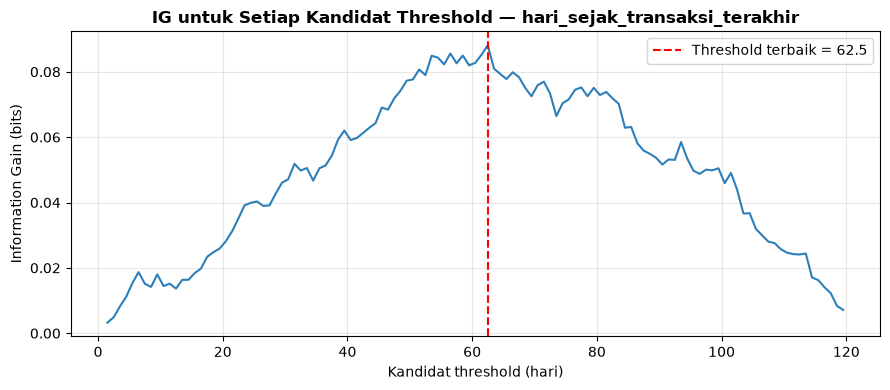

In [7]:
kolom = 'hari_sejak_transaksi_terakhir'
mask = df[kolom].notnull()
x, y = df.loc[mask, kolom], target[mask]
h_awal = hitung_entropi(y)

nilai_unik = np.sort(x.unique())
kandidat = (nilai_unik[:-1] + nilai_unik[1:]) / 2
ig_per_threshold = []
for t in kandidat:
    kiri, kanan = y[x <= t], y[x > t]
    h_cond = len(kiri) / len(y) * hitung_entropi(kiri) + len(kanan) / len(y) * hitung_entropi(kanan)
    ig_per_threshold.append(h_awal - h_cond)

ig_terbaik, t_terbaik, _ = hitung_ig_kontinu(df[kolom], target)

# Ringkasan dua kelompok hasil split terbaik
kiri, kanan = y[x <= t_terbaik], y[x > t_terbaik]
display(pd.DataFrame({
    'Kelompok': [f'<= {t_terbaik} hari', f'> {t_terbaik} hari'],
    'Jumlah Pelanggan': [len(kiri), len(kanan)],
    '% Churn': [round(kiri.mean() * 100, 1), round(kanan.mean() * 100, 1)],
    'Entropi': [round(hitung_entropi(kiri), 4), round(hitung_entropi(kanan), 4)],
}))
print(f"Jumlah kandidat threshold yang diuji : {len(kandidat)}")
print(f"Threshold terbaik                    : {t_terbaik} hari")
print(f"Information Gain terbaik             : {ig_terbaik:.5f} bits")

plt.figure(figsize=(9, 4))
plt.plot(kandidat, ig_per_threshold, color='#2c7fb8')
plt.axvline(t_terbaik, color='red', linestyle='--', label=f'Threshold terbaik = {t_terbaik}')
plt.title('IG untuk Setiap Kandidat Threshold — hari_sejak_transaksi_terakhir', fontweight='bold')
plt.xlabel('Kandidat threshold (hari)')
plt.ylabel('Information Gain (bits)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Penjelasan:**

- Ada 119 kandidat threshold yang dicoba. IG paling tinggi ada di 62,5 hari, yaitu 0,08813 bit.
- Grafiknya naik lalu turun. Threshold yang terlalu kecil atau terlalu besar membuat salah satu kelompok isinya sedikit, sehingga IG-nya kecil.
- Pelanggan yang transaksi terakhirnya ≤ 62,5 hari churn-nya 9,7%, sedangkan yang > 62,5 hari churn-nya 38,9%. Jadi pelanggan yang sudah sekitar 2 bulan tidak bertransaksi lebih berisiko churn.
- Ada 39 baris kosong yang diabaikan, jadi perhitungan memakai 961 baris dengan entropi awal 0,7887.

### 6. Hitung IG Semua Fitur

Aturan yang dipakai:
- Kolom angka dengan lebih dari 10 nilai unik dihitung sebagai numerik kontinu, sisanya kategorikal.
- IG > 0,05: Prioritas Tinggi
- 0,01 < IG ≤ 0,05: Prioritas Sedang
- IG ≤ 0,01: dibuang

Kolom `% dari H(S)` menunjukkan berapa persen entropi awal yang berkurang karena fitur tersebut.

In [8]:
def is_numerik_kontinu(series, batas_unik=10):
    # True jika kolom bisa dibaca sebagai angka DAN memiliki lebih dari 'batas_unik' nilai unik
    try:
        nilai = series.dropna().astype(float)
    except (ValueError, TypeError):
        return False
    return nilai.nunique() > batas_unik

def tentukan_status(ig):
    if ig > 0.05:
        return 'Prioritas Tinggi'
    if ig > 0.01:
        return 'Prioritas Sedang'
    return 'Dieliminasi (Lemah)'

daftar_fitur = [c for c in df.columns if c != 'churn_3bln']
hasil_ig = []

for col in daftar_fitur:
    if col == 'id_pelanggan':                    # identifier unik -> IG palsu (maksimum)
        hasil_ig.append({'Fitur': col, 'Tipe': 'Identifier',
                         'Metode': f'Nilai Unik ({df[col].nunique()} ID)',
                         'Information Gain': H_total,
                         'Status': 'Dieliminasi (Overfitting)'})
        continue

    if is_numerik_kontinu(df[col]):
        ig, t, _ = hitung_ig_kontinu(df[col], target)
        tipe, metode = 'Numerik Kontinu', f'Threshold Split (<= {t:,.1f})'
    else:
        ig, _ = hitung_ig_kategorikal(df[col], target)
        tipe, metode = 'Kategorikal / Diskrit', f'{df[col].nunique(dropna=False)} Kategori'

    hasil_ig.append({'Fitur': col, 'Tipe': tipe, 'Metode': metode,
                     'Information Gain': ig, 'Status': tentukan_status(ig)})

df_ranking = (pd.DataFrame(hasil_ig)
              .sort_values(by='Information Gain', ascending=False)
              .reset_index(drop=True))
df_ranking['% dari H(S)'] = (df_ranking['Information Gain'] / H_total * 100).round(2)
df_ranking.round({'Information Gain': 5})

,Fitur,Tipe,Metode,Information Gain,Status,% dari H(S)
0,id_pelanggan,Identifier,Nilai Unik (1000 ID),0.79835,Dieliminasi (Overfitting),100.00
1,hari_sejak_transaksi_terakhir,Numerik Kontinu,Threshold Split (<= 62.5),0.08813,Prioritas Tinggi,11.04
2,jumlah_keluhan_6bln,Kategorikal / Diskrit,6 Kategori,0.07954,Prioritas Tinggi,9.96
3,skor_kepuasan,Numerik Kontinu,Threshold Split (<= 7.0),0.06670,Prioritas Tinggi,8.35
4,jumlah_kunjungan_30hari,Numerik Kontinu,Threshold Split (<= 2.5),0.01379,Prioritas Sedang,1.73
5,jumlah_transaksi_6bln,Numerik Kontinu,Threshold Split (<= 8.5),0.01201,Prioritas Sedang,1.50
6,total_belanja_6bln_rp,Numerik Kontinu,"Threshold Split (<= 935,500.0)",0.01132,Prioritas Sedang,1.42
7,kode_acak,Numerik Kontinu,"Threshold Split (<= 1,790.5)",0.00479,Dieliminasi (Lemah),0.60
8,lama_member_bulan,Numerik Kontinu,Threshold Split (<= 43.5),0.00442,Dieliminasi (Lemah),0.55
9,kanal_akuisisi,Kategorikal / Diskrit,5 Kategori,0.00373,Dieliminasi (Lemah),0.47


**Penjelasan:**

- `id_pelanggan` ada di urutan pertama dengan IG 0,79835 (100%). Ini contoh bias yang dijelaskan di langkah 4, jadi kolom ini dibuang.
- Ada 3 fitur dengan prioritas tinggi:
  - `hari_sejak_transaksi_terakhir` (0,0881): makin lama tidak bertransaksi, makin besar kemungkinan churn.
  - `jumlah_keluhan_6bln` (0,0795): makin banyak keluhan, makin besar kemungkinan churn.
  - `skor_kepuasan` (0,0667): pelanggan dengan skor ≤ 7 lebih banyak yang churn.
- Ada 3 fitur dengan prioritas sedang: `jumlah_kunjungan_30hari`, `jumlah_transaksi_6bln`, dan `total_belanja_6bln_rp`. Ketiganya berhubungan dengan seberapa aktif pelanggan.
- Fitur lainnya IG-nya di bawah 0,01 dan dibuang. `negara` IG-nya 0 karena isinya hanya "Indonesia". `kode_acak` mendapat IG 0,0048 walaupun isinya angka acak. Ini karena ada sekitar 940 threshold yang dicoba, jadi pasti ada yang kebetulan sedikit memisahkan data. Karena itu perlu batas minimal 0,01.
- IG paling besar hanya sekitar 11% dari H(S). Ini wajar karena satu fitur saja biasanya tidak cukup untuk menjelaskan churn.

### 7. Visualisasi

Grafik IG tiap fitur (`id_pelanggan` tidak ditampilkan supaya skala grafiknya tidak rusak). Hijau = prioritas tinggi, oranye = prioritas sedang, abu-abu = dibuang.

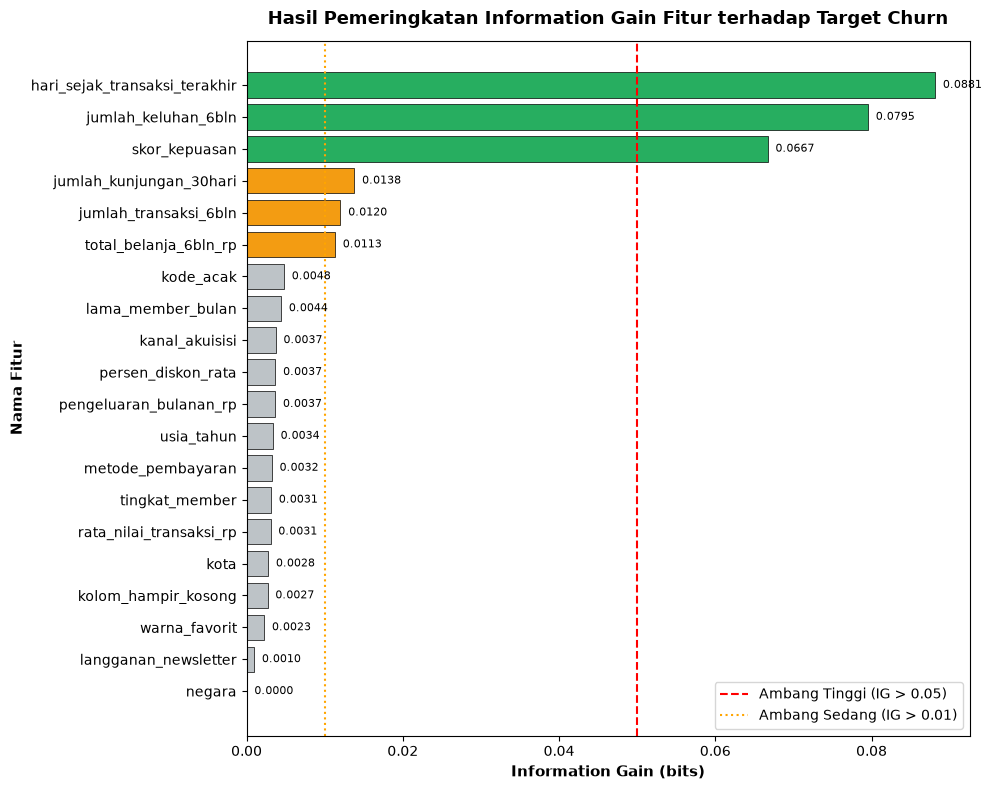

In [9]:
df_plot = (df_ranking[df_ranking['Fitur'] != 'id_pelanggan']
           .sort_values(by='Information Gain', ascending=True))

warna = ['#27ae60' if ig > 0.05 else ('#f39c12' if ig > 0.01 else '#bdc3c7')
         for ig in df_plot['Information Gain']]

plt.figure(figsize=(10, 8))
plt.barh(df_plot['Fitur'], df_plot['Information Gain'], color=warna, edgecolor='black', linewidth=0.5)
plt.axvline(x=0.05, color='red', linestyle='--', label='Ambang Tinggi (IG > 0.05)')
plt.axvline(x=0.01, color='orange', linestyle=':', label='Ambang Sedang (IG > 0.01)')

# Menampilkan nilai IG di ujung setiap batang
for nama, ig in zip(df_plot['Fitur'], df_plot['Information Gain']):
    plt.text(ig + 0.001, nama, f'{ig:.4f}', va='center', fontsize=8)

plt.title('Hasil Pemeringkatan Information Gain Fitur terhadap Target Churn',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Information Gain (bits)', fontsize=11, fontweight='bold')
plt.ylabel('Nama Fitur', fontsize=11, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Penjelasan:**

3 fitur teratas (hijau) IG-nya jauh lebih besar dari fitur lain, yaitu sekitar 0,067-0,088, sedangkan fitur ke-4 hanya 0,014. Tiga fitur oranye sedikit di atas garis 0,01. Sisanya 14 fitur abu-abu IG-nya di bawah 0,005, jadi hampir tidak ada pengaruhnya.

### 8. Pilih Fitur dan Simpan Dataset

Fitur yang dipakai adalah fitur dengan IG > 0,01, kecuali `id_pelanggan`. Hasilnya disimpan ke `Dataset_Hasil_Seleksi_Information_Gain.csv`.

In [10]:
fitur_terpilih = df_ranking[
    (df_ranking['Information Gain'] > 0.01) &
    (df_ranking['Fitur'] != 'id_pelanggan')
]['Fitur'].tolist()
fitur_dibuang = [f for f in daftar_fitur if f not in fitur_terpilih]

print(f"Fitur TERPILIH ({len(fitur_terpilih)} fitur):")
for i, f in enumerate(fitur_terpilih, 1):
    ig_val = df_ranking.loc[df_ranking['Fitur'] == f, 'Information Gain'].values[0]
    print(f"  {i}. {f:30} -> IG = {ig_val:.5f} bits")

print(f"\nFitur DIBUANG ({len(fitur_dibuang)} fitur):")
print("  " + ", ".join(fitur_dibuang))

df_hasil_seleksi = df[fitur_terpilih + ['churn_3bln']].copy()
df_hasil_seleksi.to_csv('Dataset_Hasil_Seleksi_Information_Gain.csv', index=False)
print(f"\nDataset baru disimpan ke 'Dataset_Hasil_Seleksi_Information_Gain.csv' dengan dimensi {df_hasil_seleksi.shape}.")

Fitur TERPILIH (6 fitur):
  1. hari_sejak_transaksi_terakhir  -> IG = 0.08813 bits
  2. jumlah_keluhan_6bln            -> IG = 0.07954 bits
  3. skor_kepuasan                  -> IG = 0.06670 bits
  4. jumlah_kunjungan_30hari        -> IG = 0.01379 bits
  5. jumlah_transaksi_6bln          -> IG = 0.01201 bits
  6. total_belanja_6bln_rp          -> IG = 0.01132 bits

Fitur DIBUANG (15 fitur):
  id_pelanggan, usia_tahun, kota, kanal_akuisisi, tingkat_member, metode_pembayaran, langganan_newsletter, lama_member_bulan, rata_nilai_transaksi_rp, persen_diskon_rata, pengeluaran_bulanan_rp, kode_acak, warna_favorit, negara, kolom_hampir_kosong

Dataset baru disimpan ke 'Dataset_Hasil_Seleksi_Information_Gain.csv' dengan dimensi (1000, 7).


**Penjelasan:**

- Dari 21 kolom, ada 6 fitur yang dipakai dan 15 kolom yang dibuang (`id_pelanggan` + 14 fitur dengan IG ≤ 0,01).
- Ukuran dataset baru adalah (1000, 7), yaitu 6 fitur + target. Jumlah barisnya tetap 1000.
- Dataset ini masih punya nilai kosong dan outlier, jadi masih perlu diimputasi dan dibersihkan sebelum dipakai untuk training model.

In [11]:
df_hasil_seleksi.head()

,hari_sejak_transaksi_terakhir,jumlah_keluhan_6bln,skor_kepuasan,jumlah_kunjungan_30hari,jumlah_transaksi_6bln,total_belanja_6bln_rp,churn_3bln
0,98.0,0.0,8.6,5.0,7.0,1960000.0,0
1,18.0,NaN,7.6,14.0,11.0,2486000.0,0
2,81.0,0.0,10.0,11.0,9.0,3879000.0,0
3,101.0,0.0,NaN,NaN,11.0,3564000.0,0
4,76.0,0.0,NaN,5.0,6.0,2178000.0,0


**Penjelasan:**

5 baris pertama dataset hasil seleksi. Kolom yang tersisa hanya 6 fitur terpilih dan `churn_3bln`.

### 9. Kesimpulan

Fitur yang terpilih dan pengaruhnya terhadap churn:

| Fitur | Hasil |
|---|---|
| `hari_sejak_transaksi_terakhir` | > 62,5 hari: churn 38,9%, ≤ 62,5 hari: 9,7% |
| `jumlah_keluhan_6bln` | 4 keluhan: churn 63,2%, 0 keluhan: 14,9% |
| `skor_kepuasan` | skor ≤ 7: churn 40,3%, skor > 7: 13,6% |
| `jumlah_kunjungan_30hari` | ≤ 2 kunjungan: churn 44,0%, lebih dari itu: 22,4% |
| `jumlah_transaksi_6bln` | ≤ 8 transaksi: churn 29,1%, lebih dari itu: 18,2% |
| `total_belanja_6bln_rp` | ≤ Rp935.500: churn 34,7%, lebih dari itu: 21,6% |

Pelanggan yang jarang aktif dan tidak puas paling berisiko churn. Data seperti usia, kota, warna favorit, dan negara hampir tidak berpengaruh.

Kekurangan IG:
1. Cenderung memberi nilai tinggi ke kolom dengan banyak nilai unik, contohnya `id_pelanggan` dan `kode_acak`.
2. Menilai fitur satu per satu, jadi tidak melihat hubungan antar fitur. Misalnya `jumlah_transaksi_6bln` dan `total_belanja_6bln_rp` kemungkinan saling berkaitan.
3. Batas 0,05 dan 0,01 ditentukan sendiri, jadi sebaiknya dicek lagi dengan membandingkan performa model.